In [1]:
import torch
torch.set_default_dtype(torch.float64)

def f1(x):
    return torch.exp(torch.sin(2 * torch.pi * x))

x_train = torch.linspace(-1, 1, 201).unsqueeze(1)   # shape (201, 1)
x_test  = torch.linspace(-1, 1, 601).unsqueeze(1)   # shape (601, 1)
y_train, y_test = f1(x_train), f1(x_test)

In [51]:
import torch.nn as nn

def make_mlp(width=128, depth=3, act=nn.Tanh):
    layers, d_in = [], 1
    for _ in range(depth):
        layers += [nn.Linear(d_in, width), act()]
        d_in = width
    layers.append(nn.Linear(d_in, 1))
    return nn.Sequential(*layers)

In [11]:
def trap_weights(n_points, a=-1.0, b=1.0):
    dx = (b - a) / (n_points - 1)
    w = torch.full((n_points, 1), dx)
    w[0] = w[-1] = dx / 2
    return w

w_train, w_test = trap_weights(201), trap_weights(601)

def train(model, x, y, w, epochs=2400, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        opt.zero_grad()
        loss = (w * (model(x) - y) ** 2).sum()
        loss.backward()
        opt.step()
    return model

In [13]:
torch.manual_seed(0)
model = train(make_mlp(), x_train, y_train, w_train)
with torch.no_grad():
    test_err = (w_test * (model(x_test) - y_test) ** 2).sum().sqrt()
print(test_err.item())

0.01410358595020678


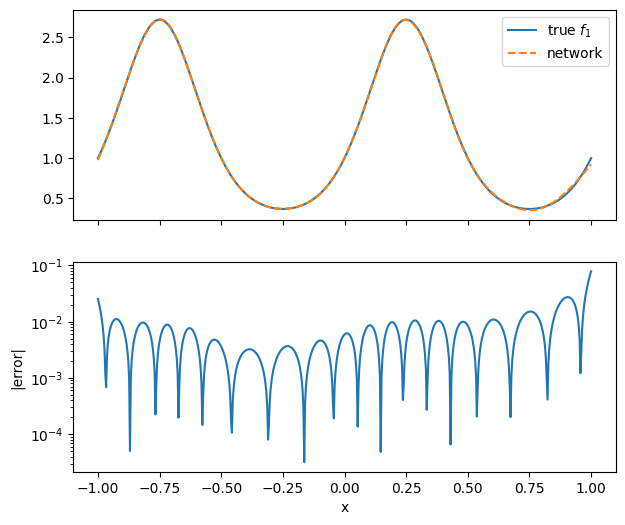

In [16]:
import matplotlib.pyplot as plt

with torch.no_grad():
    y_pred = model(x_test)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 6), sharex=True)
ax1.plot(x_test.numpy(), y_test.numpy(), label="true $f_1$")
ax1.plot(x_test.numpy(), y_pred.numpy(), "--", label="network")
ax1.legend()
ax2.plot(x_test.numpy(), (y_pred - y_test).abs().numpy())
ax2.set_yscale("log"); ax2.set_ylabel("|error|"); ax2.set_xlabel("x")
plt.show()

In [14]:
def ck_features(model, x):
    with torch.no_grad():
        z = model[:-1](x)                               # (n, 128)
    return torch.cat([z, torch.ones(len(x), 1)], dim=1) # (n, 129)

Phi_train = ck_features(model, x_train)   # (201, 129)
Phi_test  = ck_features(model, x_test)    # (601, 129)

In [15]:
readout = model[-1]
coef = torch.cat([readout.weight.flatten(), readout.bias]).detach()  # (129,)
with torch.no_grad():
    diff = Phi_test @ coef - model(x_test).flatten()
print(diff.abs().max().item())

8.881784197001252e-16


In [17]:
from torch.func import functional_call, jacrev, vmap

params = {k: v.detach() for k, v in model.named_parameters()}

def f_single(p, x):
    return functional_call(model, p, (x.unsqueeze(0),)).squeeze()

def jacobian(p, x):
    jac = vmap(jacrev(f_single), in_dims=(None, 0))(p, x)
    return torch.cat([j.reshape(len(x), -1) for j in jac.values()], dim=1)

In [18]:
J_train = jacobian(params, x_train)   # (201, 33409)
J_test  = jacobian(params, x_test)    # (601, 33409)
print(J_train.shape, (J_train[:, -129:] - Phi_train).abs().max().item())

torch.Size([201, 33409]) 6.938893903907228e-16


In [27]:
def fit_subset(J_tr, target, w, cols, rcond=1e-14):
    sw = w.sqrt()
    A = sw * J_tr[:, cols]          # weighted design matrix
    b = sw * target                 # weighted target
    return torch.linalg.lstsq(A, b, driver="gelsd", rcond=rcond).solution

In [30]:
all_cols = torch.arange(J_train.shape[1])
gamma = fit_subset(J_train, y_train, w_train, all_cols)
f_ntk_train, f_ntk_test = J_train @ gamma, J_test @ gamma

print((f_ntk_train - y_train).abs().max().item())          # interpolation check
print((w_test * (f_ntk_test - y_test) ** 2).sum().sqrt().item())  # NTK test error

2.761413320229167e-11
1.1045959886582286e-11


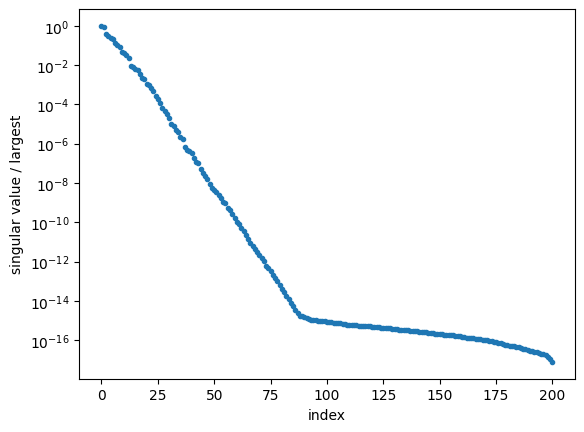

In [21]:
s = torch.linalg.svdvals(w_train.sqrt() * J_train)
plt.semilogy(s / s[0], ".")
plt.xlabel("index"); plt.ylabel("singular value / largest")
plt.show()

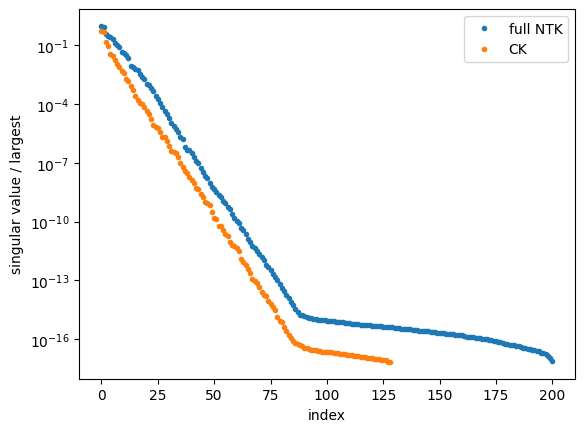

In [29]:
s_ck = torch.linalg.svdvals(w_train.sqrt() * J_train[:, -129:])
plt.semilogy(s / s[0], ".", label="full NTK")
plt.semilogy(s_ck / s[0], ".", label="CK")
plt.xlabel("index"); plt.ylabel("singular value / largest")
plt.legend(); plt.show()

In [70]:
# order = all_cols.flip(0)
# ck = torch.arange(33280, 33409)
# L1 = torch.stack([torch.arange(0, 128), torch.arange(128, 256)], dim=1).flatten()
# L2 = torch.arange(256, 16768)
# L3 = torch.arange(16768, 33280)
# order = torch.cat([ck, L1, L2, L3])
g = torch.Generator().manual_seed(0)
order = torch.randperm(J_train.shape[1], generator=g)
def test_norm(g):
    return (w_test * g ** 2).sum().sqrt().item()

In [42]:
def gad_terms(cols, rest, rcond=1e-14):
    sw = w_train.sqrt()
    gS, gU = gamma[cols], gamma[rest]

    # truncated SVD of the weighted modeled design matrix
    U, s, Vh = torch.linalg.svd(sw * J_train[:, cols], full_matrices=False)
    keep = s > rcond * s[0]
    U, s, Vh = U[:, keep], s[keep], Vh[keep]
    X = (U.T @ (sw * J_train[:, rest])) / s[:, None]
    A_norm = torch.linalg.matrix_norm(X, ord=2).item() if len(rest) > 0 else 0.0
    rank = int(keep.sum())
    # parameter-space pieces
    B_gS = Vh.T @ (Vh @ gS)
    A_gU = Vh.T @ ((U.T @ (sw * (J_train[:, rest] @ gU))) / s[:, None])
    p_data, p_alias, p_model = gS - B_gS, -A_gU, gU

    # their images at the test points
    f_data  = J_test[:, cols] @ p_data
    f_alias = J_test[:, cols] @ p_alias
    f_model = J_test[:, rest] @ p_model
    return (f_data, f_alias, f_model), (p_data, p_alias, p_model), A_norm, rank

In [38]:
for m in [40, 129]:
    cols, rest = order[:m], order[m:]
    (fd, fa, fm), _ = gad_terms(cols, rest)
    c = fit_subset(J_train, f_ntk_train, w_train, cols)
    total = f_ntk_test - J_test[:, cols] @ c
    print(m, test_norm(total), test_norm(fd), test_norm(fa),
          test_norm(fm), test_norm(fd + fa + fm - total))

40 7.243195833270017e-06 5.1601684613909494e-14 46.710483834803505 46.71048389554145 3.9098842945173806e-13
129 3.5055838506017433e-11 2.555968400610278e-13 94.3947406597104 94.39474065970965 2.7286879137459357e-11


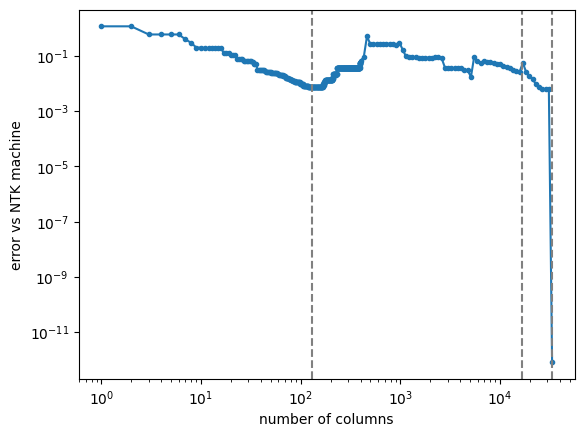

In [65]:
import numpy as np
sizes = np.unique(np.concatenate([np.arange(1, 400),
                                  np.geomspace(400, 33409, 60).astype(int)]))
errs = []

for m in sizes:
    cols = order[:m]
    c = fit_subset(J_train, f_ntk_train, w_train, cols)
    errs.append(test_norm(J_test[:, cols] @ c - f_ntk_test))
plt.loglog(sizes, errs, ".-")
for b in [129, 16641, 33153]:
    plt.axvline(b, color="gray", ls="--")
plt.xlabel("number of columns"); plt.ylabel("error vs NTK machine")
plt.show()

In [71]:
rows = []
for m in sizes:
    cols, rest = order[:m], order[m:]
    (fd, fa, fm), (pd, pa, pm), A_norm, rank = gad_terms(cols, rest)
    risk = test_norm(fd + fa + fm) ** 2
    rows.append([risk, pd.norm().item(), pa.norm().item(),
                 pm.norm().item(), A_norm, rank])
rows = np.array(rows)

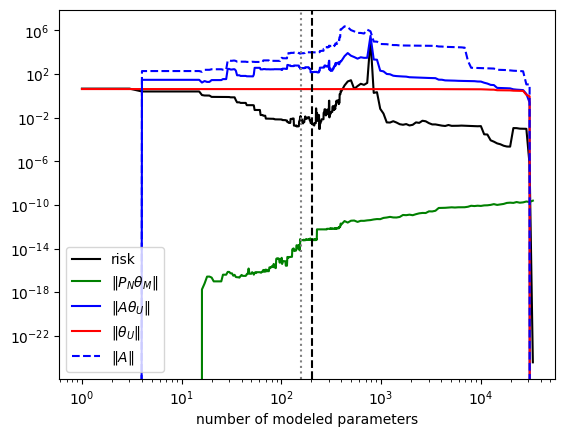

In [72]:
plt.loglog(sizes, rows[:, 0], "k-",  label="risk")
plt.loglog(sizes, rows[:, 1], "g-",  label=r"$\|P_N\theta_M\|$")
plt.loglog(sizes, rows[:, 2], "b-",  label=r"$\|A\theta_U\|$")
plt.loglog(sizes, rows[:, 3], "r-",  label=r"$\|\theta_U\|$")
plt.loglog(sizes, rows[:, 4], "b--", label=r"$\|A\|$")
# for b in [129, 16641, 33153]:
#     plt.axvline(b, color="gray", ls="--")
# for b in [129, 385, 16897]:
#     plt.axvline(b, color="gray", ls="--")
plt.axvline(201, color="k", ls="--")
plt.axvline(159, color="gray", ls=":")
plt.xlabel("number of modeled parameters"); plt.legend(); plt.show()

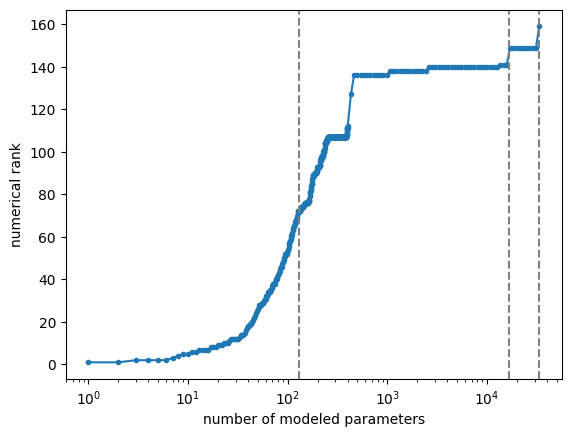

In [62]:
plt.semilogx(sizes, rows[:, 5], ".-")
for b in [129, 16641, 33153]:
    plt.axvline(b, color="gray", ls="--")
plt.xlabel("number of modeled parameters"); plt.ylabel("numerical rank"); plt.show()

In [61]:
frows = []
for m in sizes:
    cols, rest = order[:m], order[m:]
    (fd, fa, fm), _, _, _ = gad_terms(cols, rest)
    frows.append([test_norm(fd + fa + fm), test_norm(fd), test_norm(fa),
                  test_norm(fm), test_norm(fa + fm)])
frows = np.array(frows)

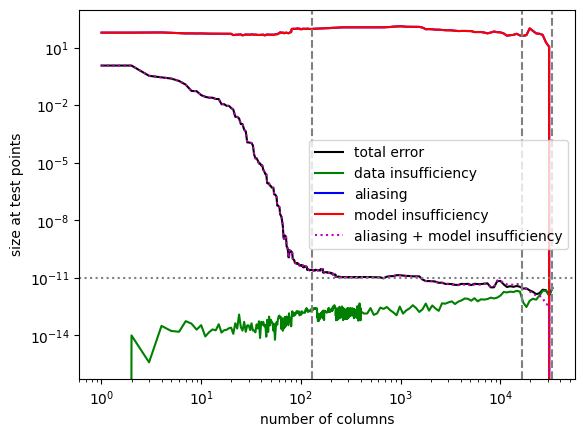

In [48]:
plt.loglog(sizes, frows[:, 0], "k-",  label="total error")
plt.loglog(sizes, frows[:, 1], "g-",  label="data insufficiency")
plt.loglog(sizes, frows[:, 2], "b-",  label="aliasing")
plt.loglog(sizes, frows[:, 3], "r-",  label="model insufficiency")
plt.loglog(sizes, frows[:, 4], "m:",  label="aliasing + model insufficiency")
plt.axhline(1e-11, color="gray", ls=":")
for b in [129, 16641, 33153]:
    plt.axvline(b, color="gray", ls="--")
plt.xlabel("number of columns"); plt.ylabel("size at test points")
plt.legend(); plt.show()

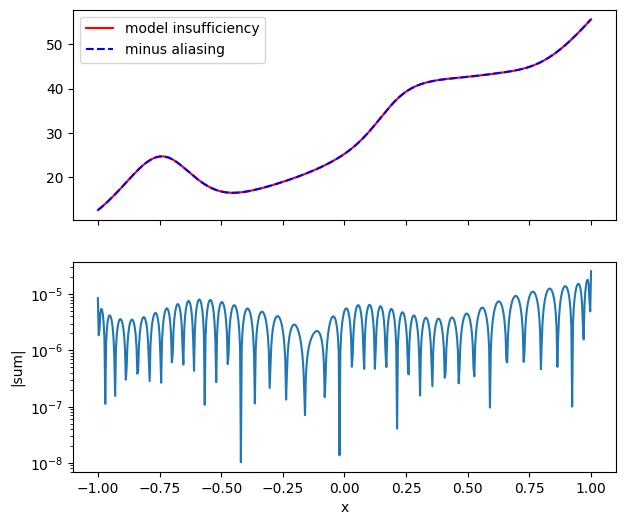

In [49]:
m = 40
(fd, fa, fm), *_ = gad_terms(order[:m], order[m:])
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 6), sharex=True)
ax1.plot(x_test.numpy(), fm.numpy(), "r-", label="model insufficiency")
ax1.plot(x_test.numpy(), -fa.numpy(), "b--", label="minus aliasing")
ax1.legend()
ax2.semilogy(x_test.numpy(), (fa + fm).abs().numpy())
ax2.set_ylabel("|sum|"); ax2.set_xlabel("x")
plt.show()

In [50]:
rows_tanh, frows_tanh = rows.copy(), frows.copy()

In [52]:
torch.manual_seed(0)
model = train(make_mlp(act=nn.ReLU), x_train, y_train, w_train)
params = {k: v.detach() for k, v in model.named_parameters()}
J_train, J_test = jacobian(params, x_train), jacobian(params, x_test)
gamma = fit_subset(J_train, y_train, w_train, all_cols)
f_ntk_train, f_ntk_test = J_train @ gamma, J_test @ gamma

In [53]:
with torch.no_grad():
    print("NN: ", test_norm(model(x_test) - y_test))
print("NTK:", test_norm(f_ntk_test - y_test))
c = fit_subset(J_train, y_train, w_train, all_cols[-129:])
print("CK: ", test_norm(J_test[:, -129:] @ c - y_test))

NN:  0.004496262648123917
NTK: 0.007498213169659552
CK:  0.003930688232854578


0.010026286701632081


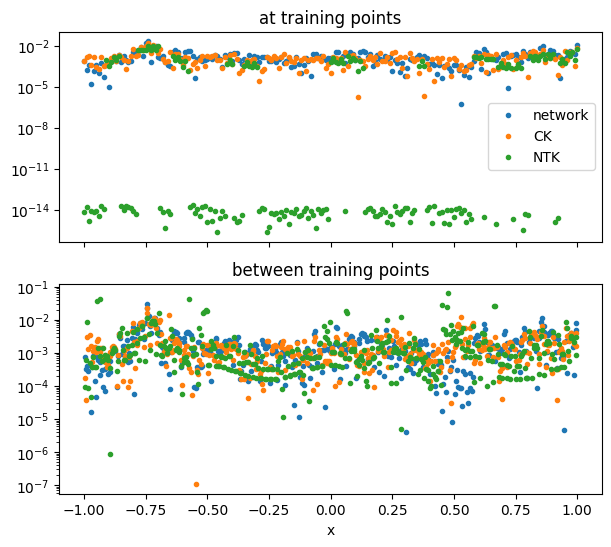

In [55]:
print((f_ntk_train - y_train).abs().max().item())   # does it interpolate?

with torch.no_grad():
    nn_err = (model(x_test) - y_test).abs()
ck_test = J_test[:, -129:] @ c
on = torch.arange(601) % 3 == 0   # test points that are also training points
ntk_err = (f_ntk_test - y_test).abs()
ck_err = (ck_test - y_test).abs()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 6), sharex=True)
for err, lab in [(nn_err, "network"), (ck_err, "CK"), (ntk_err, "NTK")]:
    ax1.semilogy(x_test[on].numpy(), err[on].numpy(), ".", label=lab)
    ax2.semilogy(x_test[~on].numpy(), err[~on].numpy(), ".", label=lab)
ax1.set_title("at training points"); ax2.set_title("between training points")
ax1.legend(); ax2.set_xlabel("x"); plt.show()

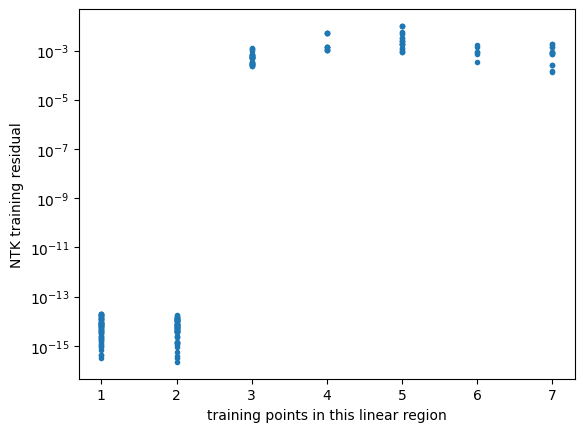

159
159


In [56]:
def activation_pattern(model, x):
    pats, h = [], x
    with torch.no_grad():
        for layer in model[:-1]:          # skip the readout
            h = layer(h)
            if isinstance(layer, nn.Linear):
                pats.append(h > 0)         # which units are on
    return torch.cat(pats, dim=1)          # (n, 384) True/False

P = activation_pattern(model, x_train)
new_region = torch.ones(201, dtype=torch.bool)
new_region[1:] = (P[1:] != P[:-1]).any(dim=1)
region_id = torch.cumsum(new_region.long(), 0)
region_size = torch.bincount(region_id)[region_id]   # size of each point's region

train_res = (f_ntk_train - y_train).abs().flatten()
plt.semilogy(region_size.numpy(), train_res.numpy(), ".")
plt.xlabel("training points in this linear region"); plt.ylabel("NTK training residual")
plt.show()

print(torch.linalg.matrix_rank(w_train.sqrt() * J_train, rtol=1e-14).item())
print(sum(min(s, 2) for s in torch.bincount(region_id)[1:].tolist()))

In [57]:
n_regions = region_id.max().item()
ck_rank = torch.linalg.matrix_rank(w_train.sqrt() * J_train[:, -129:], rtol=1e-14).item()
print(n_regions, ck_rank)

109 72


In [58]:
Z = J_train[:, -129:-1]   # last hidden layer's activations at the training points
print((Z.abs().max(dim=0).values == 0).sum().item())

57
